# Calibración independiente de A3110 y A3210

Se reutilizan las funciones del DPBE isotérmico de `MSMPR_KNO3_DPBE_sensibilidad_Pareto.ipynb`, sin ejecutar sus barridos ni copiar sus ecuaciones. `PBE_sol/PBE.py` requiere CasADi y clases; el notebook DPBE ya ofrece la formulación funcional y el cierre de ClO₄ que se necesita aquí. `solve_ivp` integra **su mismo** `dynamic_rhs`. Se conservan una población, alimentación sin semillas, salida representativa y volumen constante. No se añaden nucleación secundaria, evaporación efectiva, clasificación ni mecanismos de incorporación.

**Modo predeterminado: demostración sintética, no calibración industrial.** Cada equipo tiene parámetros propios y campañas independientes. Los datos de A3000/A6000 no se atribuyen a A3110/A3210. Los balances PFD/v6 tienen sólidos en la alimentación, recirculación y salidas no representativas: son una limitación de aplicabilidad del modelo, no datos para forzar su ajuste.

Dependencias: Python ≥3.10, numpy, pandas, scipy, matplotlib, openpyxl y un entorno Jupyter. Solo se leen los originales. Todos los resultados quedan en este notebook.

In [1]:
from pathlib import Path
from copy import deepcopy
import ast
import hashlib
import json
import math
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.integrate import solve_ivp
from scipy.optimize import least_squares
from scipy.sparse import lil_matrix
from IPython.display import display, Markdown

# CONFIGURACIÓN EDITABLE: todas las decisiones del ajuste están aquí.
PROJECT = Path(r'C:\Users\SrLeo\Desktop\SQM\Git project\CristalizadorPT')
MODEL_FILE = PROJECT / 'MSMPR_KNO3_DPBE_sensibilidad_Pareto.ipynb'
MODE = 'demo'                         # 'demo' o 'experimental'; nunca hay fallback a demo.
DATA_FILE = Path('plantilla_datos_cristalizadores.xlsx')
SEED = 20261025
SELECTED = ['kG_m_s', 'kB_m3_s_inv', 'Kd']
# inicio, inferior, superior, unidad, transformación del optimizador
PARAMETER_CONFIG = {
    'kG_m_s': (2e-7, 2e-8, 2e-6, 'm/s', 'log'),
    'g': (1.0, 0.3, 3.0, '1', 'linear'),
    'kB_m3_s_inv': (1e10, 1e8, 1e12, 'm^-3 s^-1', 'log'),
    'b': (2.0, 0.5, 4.0, '1', 'linear'),
    'Kd': (0.01, 1e-6, 0.5, '1', 'log'),
}
FIXED = {'g': 1.0, 'b': 2.0}       # resto: BASE original, mostrado al cargar.
EQUIPMENT_FIXED = {'A3110': {}, 'A3210': {}}
EQUIPMENT_INITIAL = {'A3110': {}, 'A3210': {}}  # sobreescribe inicios por equipo.
# Para cada campaña dinámica real: concentración inicial medida y población por celda.
# N0 está integrado por celda [m^-3], NO es n(L) [m^-4]. No se estima como parámetro.
INITIAL_STATES = {}  # ejemplo: {('A3110', 'campaña-1'): {'C': 180., 'N': array}}
ALLOW_BASELINE_INPUTS = False      # real: exigir operación por campaña, sin suposiciones ocultas.
INPUT_INTERPOLATION = 'previous'   # escalón causal; 'linear' solo para operación suave documentada.
VALIDATION = {'fraction': 0.25, 'min_times': 8, 'min_train_times': 5}
OPTIMIZER = {'method': 'trf', 'loss': 'linear', 'max_nfev': 90,
             'ftol': 2e-7, 'xtol': 2e-7, 'gtol': 2e-7, 'diff_step': 2e-4}
SOLVER = {'method': 'BDF', 'rtol': 2e-6, 'atol': 1e-7, 'max_step': 120.0}
NUMERICS = {}                       # vacío conserva bins=480 y Lmax=1.2 mm originales.
WEIGHTS = {}                        # pesos positivos por variable; defecto 1.
RELATIVE_ERROR = 0.03               # escala si falta desviación estándar (no es incertidumbre inferida).
ERROR_FLOORS = {'C_kg_m3': 0.5, 'crystal_flow_kg_h': 2.0, 'M_kg_m3': 0.05,
                'crystal_mass_kg': 10., 'D20_um': 1., 'D50_um': 1.,
                'D80_um': 1., 'impurity_ppm': 0.0001}
SHEETS = {'mediciones': 'observation', 'operacion': 'input'}
HEADER_ROW = 0
COLUMN_ALIASES = {'cristalizador': 'crystallizer', 'campana': 'experiment',
                  'tiempo': 'time', 'variable': 'variable', 'valor': 'value',
                  'unidad': 'unit', 'regimen': 'regime', 'base': 'basis',
                  'origen': 'origin', 'desviacion': 'sd'}
VARIABLE_ALIASES = {'D20': 'D20_um', 'D50': 'D50_um', 'D80': 'D80_um'}
# En formato ancho, declarar cada columna: (variable, unidad, rol).
WIDE_COLUMNS = {'D20_mm': ('D20_um', 'mm', 'observation'),
                'D50_mm': ('D50_um', 'mm', 'observation'),
                'D80_mm': ('D80_um', 'mm', 'observation'),
                'temperature_C': ('temperature_C', 'degC', 'input')}
TIME_UNIT = 's'                     # para columnas anchas; en formato largo usar time_unit.
plt.rcParams.update({'figure.dpi': 110, 'axes.grid': True, 'grid.alpha': .2})

## Procedencia y supuestos

Los inicios cinéticos son los del `BASE` original. Los límites de kG (0.1–10 veces), kB (0.01–100 veces) y Kd (10⁻⁶–0.5) son ventanas exploratorias, **no intervalos experimentales**. g y b permanecen fijos por defecto para reducir confusión entre coeficientes y exponentes; pueden seleccionarse explícitamente. Solo esos cinco parámetros originales son elegibles. Solubilidad, densidad, forma y operación nunca se optimizan. No se trasladan coeficientes de caras cristalinas o gotas a la salmuera industrial.

Referencias locales revisadas: notebook de estimación previo (estructura de residuos y `least_squares`), presentación *Session 3.2 Parameter estimation 2025* (errores ponderados), informe y CSV de parámetros (brechas de transferibilidad). El PFD indica aproximadamente 55 °C para A3110 y 40 °C para A3210; v6 muestra otras condiciones. No se mezclan campañas. La demo utiliza 40/38 °C y V=660 m³ del entorno ilustrativo, no valores verificados de ambos equipos. La densidad de licor original (1040 kg/m³) se conserva y queda visible, aunque los balances de planta difieren.

**Impureza:** el único mecanismo disponible en esta versión es `impurity_postprocess`, un balance de traza estacionario con Kd. Se usa exclusivamente en campañas `steady`. Las mediciones de impureza `dynamic` se reportan como excluidas, sin inventar un balance transitorio. ClO₄ en producto debe expresarse en ppm de masa de producto seco; concentración de alimentación en kg ClO₄/m³ de licor. Percentiles: base de volumen (equivalente a masa para densidad constante), nunca percentiles por número.

In [2]:
def load_model(path):
    notebook = json.loads(path.read_text(encoding='utf-8'))
    trees = [ast.parse(''.join(c['source'])) for c in notebook['cells'] if c['cell_type'] == 'code']
    namespace = {'np': np, 'pd': pd, 'math': math, 'deepcopy': deepcopy}
    constants = {'BASE', 'INITIAL', 'NUM', 'PARAMETERS'}
    functions = {'bisect_root', 'validate_parameters', 'feed', 'flow', 'cstar', 'kinetics',
                 'make_grid', 'population_terms', 'd50', 'state_metrics', 'stationary_dpbe',
                 'impurity_postprocess', 'dynamic_rhs', 'integrate'}
    nodes = []
    for tree in trees:
        for node in tree.body:
            if isinstance(node, ast.Assign) and any(isinstance(t, ast.Name) and t.id in constants for t in node.targets):
                nodes.append(node)
            elif isinstance(node, ast.FunctionDef) and node.name in functions:
                nodes.append(node)
    exec(compile(ast.Module(body=nodes, type_ignores=[]), str(path), 'exec'), namespace)
    missing = functions.difference(namespace)
    if missing:
        raise ValueError(f'Modelo incompatible: faltan {missing}')
    namespace['DPBE_CACHE'] = {}
    return namespace

MODEL = load_model(MODEL_FILE)
MODEL_SHA256 = hashlib.sha256(MODEL_FILE.read_bytes()).hexdigest()
BASE = deepcopy(MODEL['BASE'])
NUM = {**MODEL['NUM'], **NUMERICS}
ALLOWED = {'kG_m_s', 'g', 'kB_m3_s_inv', 'b', 'Kd'}
if not set(SELECTED) <= ALLOWED or len(SELECTED) != len(set(SELECTED)):
    raise ValueError('Seleccionar parámetros originales únicos de nucleación, crecimiento o Kd.')
if not set(FIXED) <= set(BASE) or any(not set(v) <= set(BASE) for v in EQUIPMENT_FIXED.values()):
    raise ValueError('Parámetro fijo desconocido.')
for k in SELECTED:
    x, lo, hi, unit, transform = PARAMETER_CONFIG[k]
    if not 0 < lo < x < hi or transform not in ('log', 'linear'):
        raise ValueError(f'Inicio/límites inválidos: {k}')
print('Modelo original SHA256:', MODEL_SHA256)
display(pd.DataFrame([{'parámetro fijo': k, 'valor': str(v)} for k, v in {**BASE, **FIXED}.items() if k not in SELECTED]))
print('Malla:', NUM['bins'], 'celdas; Lmax =', NUM['Lmax_m'], 'm')

Modelo original SHA256: 303bda06b4f355d6e218c75760faf5f7866228c4261601bb53212e077dadace3


,parámetro fijo,valor
0,volume_m3,660.0
1,feed_dilution_fraction,0.05
2,crystallizer_temperature_C,40.0
3,residence_time,8460.63454759107
4,feed_stock_kg_m3,"{'KNO3': 220.0, 'ClO4': 0.003799262673}"
5,reference_temperature_C,40.0
6,Cstar_ref_kg_m3,180.0
7,solubility_slope_K_inv,0.01
8,g,1.0
9,b,2.0


Malla: 480 celdas; Lmax = 0.0012 m


## Datos y unidades

La plantilla usa filas largas y hojas `mediciones`/`operacion`. Identificadores obligatorios: `crystallizer`, `experiment`, `time`, `time_unit`, `regime` (`dynamic` o `steady`). Cada fila contiene `variable`, `value`, `unit`, `basis`, `origin` y `sd` opcional, en la misma unidad que value. Se admiten alias configurables y formato ancho mediante `WIDE_COLUMNS`. En fechas, time puede ser fecha/hora ISO: el origen es la primera entrada de cada campaña y debe coincidir con el estado inicial. Con tiempo numérico, cero es el inicio físico, aunque no haya observación en cero.

Los faltantes quedan ausentes. Se rechazan unidades desconocidas, duplicados ambiguos, tiempos negativos, bases incorrectas y valores no físicos. Las filas `interpolated` nunca entran en el objetivo. Solo se interpola **operación**, entre sus registros, con escalón causal por defecto y sin extrapolar. Para entradas constantes basta un registro inicial en cero. No se interpola ninguna medición. Los balances industriales no se importan como series temporales automáticamente.

In [3]:
UNITS = {
    'temperature_C': {'degC': (1., 0.), '°C': (1., 0.), 'K': (1., -273.15)},
    'feed_flow_m3_s': {'m3/s': (1., 0.), 'm3/h': (1/3600, 0.)},
    'residence_time': {'s': (1., 0.), 'min': (60., 0.), 'h': (3600., 0.)},
    'volume_m3': {'m3': (1., 0.)},
    'rho_liquid_kg_m3': {'kg/m3': (1., 0.), 'g/cm3': (1000., 0.), 't/m3': (1000., 0.)},
    'feed_KNO3_kg_m3': {'kg/m3': (1., 0.), 'g/L': (1., 0.)},
    'feed_ClO4_kg_m3': {'kg/m3': (1., 0.), 'mg/L': (.001, 0.)},
    'feed_dilution_fraction': {'1': (1., 0.), '%': (.01, 0.)},
    'C_kg_m3': {'kg/m3': (1., 0.), 'g/L': (1., 0.)},
    'M_kg_m3': {'kg/m3': (1., 0.), 'g/L': (1., 0.)},
    'crystal_mass_kg': {'kg': (1., 0.), 't': (1000., 0.)},
    'crystal_flow_kg_h': {'kg/h': (1., 0.), 'kg/s': (3600., 0.), 't/h': (1000., 0.)},
    **{k: {'um': (1., 0.), 'µm': (1., 0.), 'mm': (1000., 0.), 'm': (1e6, 0.)}
       for k in ['D20_um', 'D50_um', 'D80_um']},
    'impurity_ppm': {'ppm': (1., 0.), 'mg/kg': (1., 0.)},
}
INPUTS = {'temperature_C', 'feed_flow_m3_s', 'residence_time', 'volume_m3',
          'rho_liquid_kg_m3', 'feed_KNO3_kg_m3', 'feed_ClO4_kg_m3', 'feed_dilution_fraction'}
OUTPUTS = set(ERROR_FLOORS)
def tidy_sheet(frame, role):
    frame = frame.rename(columns=COLUMN_ALIASES).copy()
    if 'value' in frame:
        frame['role'] = role
        return frame
    pieces = []
    for col, (variable, unit, item_role) in WIDE_COLUMNS.items():
        if col in frame:
            block = frame.drop(columns=list(WIDE_COLUMNS), errors='ignore').copy()
            block['value'], block['variable'], block['unit'], block['role'] = frame[col], variable, unit, item_role
            block['basis'] = 'volume' if variable.startswith('D') else 'model'
            pieces.append(block)
    if not pieces:
        raise ValueError('Sin columnas largas o columnas declaradas en WIDE_COLUMNS.')
    return pd.concat(pieces, ignore_index=True)

def normalize_data(frame, mode):
    d = frame.copy().dropna(subset=['value'])
    required = {'crystallizer', 'experiment', 'time', 'regime', 'variable', 'unit', 'role'}
    if required.difference(d.columns):
        raise ValueError(f'Columnas faltantes: {required.difference(d.columns)}')
    if d.empty:
        raise ValueError('No hay valores cargados. La plantilla está vacía.')
    if d[list(required)].isna().any().any():
        raise ValueError('Identificador, tiempo, variable o unidad vacíos en una fila con valor.')
    for k, default in [('origin', 'measured'), ('basis', 'model'), ('sd', np.nan), ('time_unit', TIME_UNIT)]:
        if k not in d:
            d[k] = default
        else:
            d[k] = d[k].fillna(default)
    d['crystallizer'] = d.crystallizer.astype(str).str.strip().str.upper()
    d['experiment'] = d.experiment.astype(str).str.strip()
    if (d.experiment == '').any():
        raise ValueError('Nombre de campaña vacío.')
    for k in ['origin', 'role', 'regime', 'basis']:
        d[k] = d[k].astype(str).str.strip().str.lower()
    if not set(d.crystallizer) <= {'A3110', 'A3210'}:
        raise ValueError('Identificador distinto de A3110/A3210; no se reasignan áreas automáticamente.')
    if not set(d.regime) <= {'steady', 'dynamic'} or not set(d.role) <= {'input', 'observation'}:
        raise ValueError('regime o role desconocido.')
    if not set(d.origin) <= {'measured', 'synthetic', 'interpolated'}:
        raise ValueError('origin debe ser measured/synthetic/interpolated.')
    if mode == 'experimental' and (d.origin == 'synthetic').any():
        raise ValueError('Se prohíbe mezclar datos sintéticos y experimentales.')
    d['variable'] = d.variable.replace(VARIABLE_ALIASES)
    d['value'] = pd.to_numeric(d.value, errors='raise')
    d['sd'] = pd.to_numeric(d.sd, errors='raise')
    if not np.isfinite(d.value).all() or (d.sd.dropna() <= 0).any() or np.isinf(d.sd).any():
        raise ValueError('Valor no finito o sd no positiva.')
    for idx, row in d.iterrows():
        unit = str(row.unit).strip()
        if row.variable not in UNITS or unit not in UNITS[row.variable]:
            raise ValueError(f'Unidad/variable desconocida: {row.variable} [{unit}]')
        a, b = UNITS[row.variable][unit]
        d.loc[idx, 'value'] = row.value*a+b
        d.loc[idx, 'sd'] = row.sd*abs(a)
        if row.variable in INPUTS and row.role != 'input' or row.variable in OUTPUTS and row.role != 'observation':
            raise ValueError(f'Rol incompatible para {row.variable}')
        if row.variable.startswith('D') and row.basis != 'volume':
            raise ValueError('Percentiles requieren basis=volume.')
        if row.variable == 'impurity_ppm' and row.basis != 'dry_clo4':
            raise ValueError('Impureza requiere basis=dry_ClO4.')
    d['time'] = d.time.astype(object)
    for _, group in d.groupby(['crystallizer', 'experiment']):
        if group.regime.nunique() != 1:
            raise ValueError('Una campaña debe tener un único régimen.')
        numeric = pd.to_numeric(group.time, errors='coerce')
        if numeric.notna().all():
            factors = group.time_unit.map({'s': 1., 'min': 60., 'h': 3600.})
            if factors.isna().any():
                raise ValueError('Unidad temporal desconocida.')
            times = numeric*factors
        else:
            times = pd.to_datetime(group.time, errors='raise', utc=True)
            times = (times-times.min()).dt.total_seconds()
        d.loc[group.index, 'time'] = times.astype(float)
    d['time'] = d.time.astype(float)
    if not np.isfinite(d.time).all() or (d.time < 0).any():
        raise ValueError('Tiempo no finito/negativo.')
    temp = d.variable == 'temperature_C'
    if (d.loc[temp, 'value'] <= -273.15).any() or (d.loc[~temp, 'value'] < 0).any():
        raise ValueError('Medición no física.')
    positive = d.variable.isin(['feed_flow_m3_s', 'volume_m3', 'residence_time', 'rho_liquid_kg_m3'])
    if (d.loc[positive, 'value'] <= 0).any() or (d.loc[d.variable == 'feed_dilution_fraction', 'value'] >= 1).any():
        raise ValueError('Operación no física.')
    keys = ['crystallizer', 'experiment', 'time', 'role', 'variable']
    if d.duplicated(keys).any():
        raise ValueError('Duplicado ambiguo: consolidar réplicas y su sd antes de importar.')
    for _, group in d[d.role == 'observation'].groupby(keys[:3]):
        v = group.set_index('variable').value
        sizes = [v[k] for k in ['D20_um', 'D50_um', 'D80_um'] if k in v]
        if any(np.diff(sizes) < 0):
            raise ValueError('Percentiles desordenados.')
    return d.sort_values(keys).reset_index(drop=True)

def read_experiments(path):
    frames = pd.read_excel(path, sheet_name=None, header=HEADER_ROW)
    blocks = [tidy_sheet(frames[s], role) for s, role in SHEETS.items() if s in frames]
    if not blocks:
        raise ValueError(f'No aparecen hojas configuradas: {list(SHEETS)}')
    return normalize_data(pd.concat(blocks, ignore_index=True), 'experimental')

In [4]:
def parameters_for(equipment, values=None):
    p = deepcopy(BASE)
    p.update(FIXED)
    p.update(EQUIPMENT_FIXED[equipment])
    for k in SELECTED:
        p[k] = EQUIPMENT_INITIAL[equipment].get(k, PARAMETER_CONFIG[k][0])
    p.update(values or {})
    MODEL['validate_parameters'](p)
    return p

def operation_at(inputs, time, base):
    return make_operation_reader(inputs, base)(time)

def make_operation_reader(inputs, base):
    if INPUT_INTERPOLATION not in ('linear', 'previous'):
        raise ValueError('INPUT_INTERPOLATION desconocido.')
    series = {k: (g.sort_values('time').time.to_numpy(), g.sort_values('time').value.to_numpy())
              for k,g in inputs.groupby('variable')}
    def read(time):
        p = deepcopy(base)
        values = {}
        for variable,(t,v) in series.items():
            if time < t[0]-1e-8 or len(t) > 1 and time > t[-1]+1e-8:
                raise ValueError(f'Operación sin cobertura: {variable}, {time:g} s.')
            values[variable] = np.interp(time,t,v) if INPUT_INTERPOLATION == 'linear' else v[max(0,np.searchsorted(t,time+1e-8,side='right')-1)]
        for variable,value in values.items():
            if variable in ['feed_KNO3_kg_m3','feed_ClO4_kg_m3']:
                p['feed_stock_kg_m3'][{'feed_KNO3_kg_m3':'KNO3','feed_ClO4_kg_m3':'ClO4'}[variable]] = value
            elif variable != 'feed_flow_m3_s':
                p[{'temperature_C':'crystallizer_temperature_C'}.get(variable,variable)] = value
        if 'feed_flow_m3_s' in values:
            tau = p['volume_m3']/values['feed_flow_m3_s']
            if 'residence_time' in values and not np.isclose(tau,values['residence_time'],rtol=.03):
                raise ValueError('Q, V y tau inconsistentes (>3%).')
            p['residence_time'] = tau
        MODEL['validate_parameters'](p)
        return p
    return read

def validate_campaign(data, equipment, experiment):
    inputs = data[data.role == 'input']
    variables = set(inputs.variable)
    if MODE == 'experimental' and not ALLOW_BASELINE_INPUTS:
        required = {'temperature_C', 'volume_m3', 'feed_KNO3_kg_m3', 'feed_dilution_fraction'}
        if required-variables or not variables.intersection({'residence_time', 'feed_flow_m3_s'}):
            raise ValueError(f'{equipment}/{experiment}: falta operación {required-variables} y/o Q/tau.')
        if (data.variable == 'impurity_ppm').any() and not {'feed_ClO4_kg_m3','rho_liquid_kg_m3'} <= variables:
            raise ValueError('Kd requiere concentración de ClO4 y densidad de licor de la campaña.')
    if data.regime.iloc[0] == 'dynamic':
        volumes = inputs[inputs.variable == 'volume_m3'].value
        if volumes.nunique() > 1:
            raise ValueError('El modelo original exige volumen constante en una campaña dinámica.')
        if MODE == 'experimental' and (equipment, experiment) not in INITIAL_STATES:
            raise ValueError(f'Falta INITIAL_STATES para {equipment}/{experiment}.')
    return inputs

def percentile(N, grid, fraction):
    # Misma integración por celda y base de volumen que d50 original, generalizada a D20/D80.
    weights = grid['q'][3]*N
    cumulative = np.cumsum(weights)
    if cumulative[-1] <= 0:
        return np.nan
    target = fraction*cumulative[-1]
    i = min(np.searchsorted(cumulative, target), len(N)-1)
    before = cumulative[i-1] if i else 0.
    a, b = grid['edges'][i:i+2]
    return 1e6*(a**4+(target-before)/weights[i]*(b**4-a**4))**.25

def simulate_campaign(data, p, times):
    equipment, experiment = data[['crystallizer','experiment']].iloc[0]
    inputs = validate_campaign(data, equipment, experiment)
    times = np.unique(np.asarray(times, float))
    regime = data.regime.iloc[0]
    operation_at(inputs, 0., p)
    operation_at(inputs, times[-1], p)
    read_operation = make_operation_reader(inputs, p)
    grid = MODEL['make_grid'](p, NUM)
    if regime == 'dynamic':
        initial = INITIAL_STATES.get((equipment, experiment), {'C': MODEL['INITIAL']['C_kg_m3'], 'N': np.zeros(NUM['bins'])})
        N0 = np.asarray(initial['N'], float)
        if N0.shape != (NUM['bins'],) or (N0 < 0).any() or not np.isfinite(N0).all() or initial['C'] < 0:
            raise ValueError('Estado inicial incompatible con la malla o no físico.')
        y = np.r_[initial['C'], N0, np.zeros(3)]
        n = len(y)
        sparsity = lil_matrix((n, n), dtype=int)
        sparsity[0, :NUM['bins']+1] = 1
        for i in range(1, NUM['bins']+1):
            sparsity[i, 0] = sparsity[i, i] = 1
            if i > 1:
                sparsity[i, i-1] = 1
        sparsity[-3, 0] = 1
        sparsity[-2, 1:NUM['bins']+1] = 1
        sparsity[-1, NUM['bins']] = sparsity[-1, 0] = 1
        # Cortar en cada cambio operacional evita integrar a través de discontinuidades.
        knots = np.unique(np.r_[0., inputs.time, times[-1]])
        knots = knots[(knots >= 0) & (knots <= times[-1])]
        states = {0.: y.copy()}
        for left, right in zip(knots[:-1], knots[1:]):
            wanted = times[(times > left) & (times <= right)]
            sample = np.unique(np.r_[wanted, right])
            def rhs(t, state):
                # El extremo derecho pertenece al siguiente escalón solo tras reiniciar.
                clock = min(t, np.nextafter(right, left)) if INPUT_INTERPOLATION == 'previous' else t
                return MODEL['dynamic_rhs'](state, read_operation(clock), grid)
            result = solve_ivp(rhs, (left, right), y, t_eval=sample,
                               jac_sparsity=sparsity.tocsr(), **SOLVER)
            if not result.success or not np.isfinite(result.y).all():
                raise RuntimeError(f'Integración fallida: {result.message}')
            if result.y[0].min() < -1e-6 or result.y[1:-3].min() < -1e-3:
                raise ValueError('Integración con estado negativo: revisar tolerancias.')
            states.update({float(t): v for t, v in zip(result.t, result.y.T)})
            y = result.y[:, -1]
    records, distributions = [], []
    for time in times:
        q = operation_at(inputs, time, p)
        if regime == 'steady':
            dpbe = MODEL['stationary_dpbe'](q, NUM)
            C, N = dpbe['C'], dpbe['N']
        else:
            state = states[float(time)]
            C, N = state[0], np.maximum(state[1:-3], 0.)
            dpbe = {'metrics': MODEL['state_metrics'](C, N, q, grid)}
            dpbe['metrics']['tail_kg_m3_s'] = MODEL['population_terms'](C, N, q, grid)[2]
        metrics = dict(dpbe['metrics'])
        metrics.update(D20_um=percentile(N, grid, .2), D80_um=percentile(N, grid, .8),
                       crystal_mass_kg=metrics['M_kg_m3']*q['volume_m3'])
        metrics['impurity_ppm'] = MODEL['impurity_postprocess'](q, dpbe)['impurity_ppm'] if regime == 'steady' else np.nan
        _, formation, tail, _ = MODEL['population_terms'](C, N, q, grid)
        if regime == 'dynamic':
            state = states[float(time)]
            metrics['mass_inventory_kg_m3'] = C+metrics['M_kg_m3']+state[-3:].sum()
        metrics.update(time=time, tail_fraction=tail/max(abs(formation), 1e-30))
        records.append(metrics)
        distributions.append(N.copy())
    return pd.DataFrame(records).set_index('time'), np.asarray(distributions), grid

def predict(observations, all_data, p):
    predicted = pd.Series(index=observations.index, dtype=float)
    for experiment, rows in observations.groupby('experiment'):
        data = all_data[all_data.experiment == experiment]
        trajectory, _, _ = simulate_campaign(data, p, rows.time)
        for idx, row in rows.iterrows():
            predicted.loc[idx] = trajectory.loc[row.time, row.variable]
    if not np.isfinite(predicted).all():
        raise ValueError('Predicción indefinida: revisar producto, tiempos y régimen de impureza.')
    return predicted

In [5]:
def make_demo(seed=SEED):
    rng = np.random.default_rng(seed)
    rows, truth = [], {}
    for equipment, factors in [('A3110', (1.25, .8, 1.4)), ('A3210', (.85, 1.3, .75))]:
        p = parameters_for(equipment)
        p.update(kG_m_s=BASE['kG_m_s']*factors[0], kB_m3_s_inv=BASE['kB_m3_s_inv']*factors[1], Kd=BASE['Kd']*factors[2])
        truth[equipment] = {k: p[k] for k in ALLOWED}
        for experiment, regime in [('arranque_demo', 'dynamic'), ('estable_demo', 'steady')]:
            times = BASE['residence_time']*np.array([.15,.32,.57,.85,1.2,1.65,2.2,2.9,3.8,4.9,6.1,7.5])
            temperature = 40. if equipment == 'A3110' else 38.
            operation = {'temperature_C': (temperature, 'degC'), 'volume_m3': (BASE['volume_m3'], 'm3'),
                         'residence_time': (BASE['residence_time'], 's'),
                         'feed_KNO3_kg_m3': (BASE['feed_stock_kg_m3']['KNO3'], 'kg/m3'),
                         'feed_ClO4_kg_m3': (BASE['feed_stock_kg_m3']['ClO4'], 'kg/m3'),
                         'rho_liquid_kg_m3': (BASE['rho_liquid_kg_m3'], 'kg/m3'),
                         'feed_dilution_fraction': (BASE['feed_dilution_fraction'], '1')}
            common = dict(crystallizer=equipment, experiment=experiment, regime=regime, origin='synthetic', time_unit='s')
            local = [{**common, 'time': 0., 'variable': k, 'value': v, 'unit': u, 'basis': 'model', 'role': 'input', 'sd': np.nan}
                     for k,(v,u) in operation.items()]
            # Variación suave y acotada de T solo para corridas estacionarias independientes.
            # Interpolación de operación: 3 puntos de diseño, nunca observaciones interpoladas.
            if regime == 'steady':
                local = [r for r in local if r['variable'] != 'temperature_C']
                local += [{**common, 'time': t, 'variable': 'temperature_C', 'value': v,
                           'unit': 'degC', 'basis': 'model', 'role': 'input', 'sd': np.nan}
                          for t,v in zip([0., times[5], times[-1]], [temperature-1.,temperature,temperature+1.])]
            inputs = pd.DataFrame(local)
            trajectory, _, _ = simulate_campaign(inputs, p, times)
            variables = ['C_kg_m3','crystal_flow_kg_h','D20_um','D50_um','D80_um']
            if regime == 'steady':
                variables += ['impurity_ppm']
            for t in times:
                for variable in variables:
                    if rng.random() < .12:
                        continue
                    exact = trajectory.loc[t, variable]
                    sd = max(abs(exact)*.02, ERROR_FLOORS[variable]*.2)
                    value = max(0., exact+rng.normal(0.,sd))
                    unit = 'um' if variable.startswith('D') else {'C_kg_m3':'kg/m3','crystal_flow_kg_h':'kg/h','impurity_ppm':'ppm'}[variable]
                    basis = 'volume' if variable.startswith('D') else ('dry_ClO4' if variable == 'impurity_ppm' else 'model')
                    local.append({**common, 'time': t, 'variable': variable, 'value': value,
                                  'unit': unit, 'basis': basis, 'role': 'observation', 'sd': sd})
            # El ruido puede cruzar percentiles próximos al inicio; mantener solo tripletas ordenadas.
            f = pd.DataFrame(local)
            for t,g in f[f.role == 'observation'].groupby('time'):
                ix = g[g.variable.str.startswith('D')].sort_values('variable').index
                if np.any(np.diff(f.loc[ix, 'value']) < 0):
                    f = f.drop(ix)
            rows.extend(f.to_dict('records'))
    return normalize_data(pd.DataFrame(rows), 'demo'), truth

if MODE == 'demo':
    demo_data, DEMO_TRUTH = make_demo()
    experimental_data = None
    DATA = demo_data
elif MODE == 'experimental':
    experimental_data = read_experiments(DATA_FILE)
    demo_data, DEMO_TRUTH = None, None
    DATA = experimental_data
else:
    raise ValueError('MODE debe ser demo o experimental.')
OBSERVATIONS = DATA[(DATA.role == 'observation') & DATA.origin.isin(['measured','synthetic'])].copy()
excluded = OBSERVATIONS[(OBSERVATIONS.variable == 'impurity_ppm') & (OBSERVATIONS.regime != 'steady')]
if len(excluded):
    warnings.warn(f'{len(excluded)} observaciones de impureza transitoria excluidas: cierre solo estacionario.')
OBSERVATIONS = OBSERVATIONS.drop(excluded.index)
display(DATA.groupby(['crystallizer','regime','role','origin']).size().rename('filas').to_frame())
print('Observaciones excluidas por interpolación:', len(DATA[(DATA.role == 'observation') & (DATA.origin == 'interpolated')]))

filas
crystallizer regime  role        origin          
A3110        dynamic input       synthetic      7
                     observation synthetic     53
             steady  input       synthetic      9
                     observation synthetic     65
A3210        dynamic input       synthetic      7
                     observation synthetic     51
             steady  input       synthetic      9
                     observation synthetic     62

Observaciones excluidas por interpolación: 0


## Ajuste y evaluación

Se minimiza la suma de cuadrados de `(predicción − observación)/escala`, multiplicada por el peso de variable y dividida por su número de observaciones de entrenamiento. Una sd registrada prevalece; en su ausencia, escala = máximo entre error relativo × mediana absoluta **de entrenamiento** y piso editable. Así, una variable muestreada más veces no domina automáticamente. Los parámetros positivos se optimizan en logaritmo; g/b, si se seleccionan, en escala lineal.

Validación: últimas fechas de cada campaña, sin dividir variables del mismo instante entre entrenamiento y validación. Los parámetros y las escalas se calculan solo con entrenamiento. La simulación de validación continúa desde el estado inicial, sin reiniciarlo con observaciones futuras. En régimen steady cada registro representa un estado estacionario independiente; su validación temporal comprueba transferencia entre condiciones y fechas, no un transitorio. No se reajusta con validación al final.

Se utiliza el Jacobiano que ya entrega el optimizador para alertar rango deficiente y mala condición (sin barridos ni análisis de sensibilidad adicional). No se reportan intervalos de confianza cuando no están sustentados. Una convergencia numérica no demuestra identificabilidad ni validez industrial.

In [6]:
def split_temporal(observations):
    train = pd.Series(True, index=observations.index)
    notes = []
    for experiment, rows in observations.groupby('experiment'):
        times = np.sort(rows.time.unique())
        nvalid = max(1, int(np.ceil(len(times)*VALIDATION['fraction'])))
        if len(times) >= VALIDATION['min_times'] and len(times)-nvalid >= VALIDATION['min_train_times']:
            train.loc[rows.index] = rows.time < times[-nvalid]
        else:
            notes.append(f'{experiment}: sin validación temporal por pocos tiempos.')
    return train, notes

def fit_equipment(equipment, data, observations):
    p0 = parameters_for(equipment)
    train_mask, notes = split_temporal(observations)
    train = observations[train_mask]
    names = list(SELECTED)
    if 'Kd' in names and not (train.variable == 'impurity_ppm').any():
        names.remove('Kd')
        notes.append('Kd fijo: no hay impureza estacionaria en entrenamiento.')
    if not names or len(train) <= len(names):
        raise ValueError(f'{equipment}: información insuficiente ({len(train)} observaciones, {len(names)} parámetros).')
    if not set(train.variable).intersection({'D20_um','D50_um','D80_um'}):
        notes.append('Sin tamaños: nucleación y crecimiento pueden confundirse.')
    transforms = [PARAMETER_CONFIG[k][4] for k in names]
    def pack(values):
        return np.array([np.log(v) if tr == 'log' else v for v,tr in zip(values,transforms)])
    def unpack(x):
        return {k: float(np.exp(v) if tr == 'log' else v) for k,v,tr in zip(names,x,transforms)}
    lower = pack([PARAMETER_CONFIG[k][1] for k in names])
    upper = pack([PARAMETER_CONFIG[k][2] for k in names])
    x0 = pack([p0[k] for k in names])
    if np.any(x0 <= lower) or np.any(x0 >= upper):
        raise ValueError('Inicio por equipo fuera de límites.')
    scales = {v: max(RELATIVE_ERROR*rows.value.abs().median(), ERROR_FLOORS[v]) for v,rows in train.groupby('variable')}
    scale = train.sd.fillna(train.variable.map(scales)).to_numpy()
    counts = train.variable.map(train.variable.value_counts()).to_numpy()
    weights = train.variable.map(lambda v: WEIGHTS.get(v,1.)).to_numpy(float)
    if np.any(weights <= 0) or not np.isfinite(weights).all():
        raise ValueError('Pesos deben ser positivos y finitos.')
    factor = np.sqrt(weights/counts)/scale
    evaluations = []
    def residual(x):
        p = deepcopy(p0)
        p.update(unpack(x))
        values = (predict(train, data, p).to_numpy()-train.value.to_numpy())*factor
        evaluations.append(float(values@values))
        MODEL['DPBE_CACHE'].clear()
        return values
    initial_residual = residual(x0)
    result = least_squares(residual, x0, bounds=(lower,upper), **OPTIMIZER)
    pfit = {**p0, **unpack(result.x)}
    pred0, predfit = predict(observations, data, p0), predict(observations, data, pfit)
    compared = observations.copy()
    compared['initial'], compared['calibrated'] = pred0, predfit
    compared['subset'] = np.where(train_mask,'entrenamiento','validacion')
    stats = []
    for (subset,variable), g in compared.groupby(['subset','variable']):
        e0, e1 = (g.initial-g.value).to_numpy(), (g.calibrated-g.value).to_numpy()
        rmse0, rmse1 = np.sqrt(np.mean(e0**2)), np.sqrt(np.mean(e1**2))
        mae0, mae1 = np.mean(abs(e0)), np.mean(abs(e1))
        stats.append(dict(subset=subset, variable=variable, unit=next(iter(UNITS[variable])), n=len(g),
                          RMSE_initial=rmse0, RMSE_final=rmse1, MAE_initial=mae0, MAE_final=mae1,
                          RMSE_improvement_pct=100*(1-rmse1/rmse0) if rmse0 > 0 else np.nan,
                          MAE_improvement_pct=100*(1-mae1/mae0) if mae0 > 0 else np.nan))
    parameter_table = pd.DataFrame([dict(parameter=k, initial=p0[k], lower=PARAMETER_CONFIG[k][1],
                                        upper=PARAMETER_CONFIG[k][2], optimized=pfit[k], unit=PARAMETER_CONFIG[k][3],
                                        status='ajustado' if k in names else 'fijo por falta de datos') for k in SELECTED])
    singular = np.linalg.svd(result.jac, compute_uv=False)
    rank = int(np.sum(singular > singular[0]*1e-7)) if len(singular) and singular[0] > 0 else 0
    condition = singular[0]/singular[-1] if len(singular) and singular[-1] > 0 else np.inf
    if rank < len(names) or condition > 1e6:
        notes.append(f'Identificabilidad débil: rango {rank}/{len(names)}, condición {condition:.2g}.')
    if np.any(result.active_mask) or np.any(np.minimum(result.x-lower,upper-result.x)/(upper-lower) < .01):
        notes.append('Parámetro próximo a límite: revisar dominio y datos.')
    if not result.success:
        notes.append(f'Optimizador sin convergencia: {result.message}')
    if (observations.variable == 'impurity_ppm').any():
        notes.append('Kd describe solamente el cierre estacionario de ClO4 en producto seco.')
    notes.append('Solubilidad, rho y kv son fijos: errores en ellos pueden sesgar la cinética.')
    return dict(parameters=pfit, initial=p0, parameter_table=parameter_table, performance=pd.DataFrame(stats),
                comparison=compared, optimizer=result, initial_cost=float(initial_residual@initial_residual),
                final_cost=float(result.fun@result.fun), notes=notes, rank=rank, condition=condition,
                names=names, data=data, evaluations=len(evaluations))

RESULTS = {}
for equipment in ['A3110','A3210']:
    data = DATA[DATA.crystallizer == equipment]
    obs = OBSERVATIONS[OBSERVATIONS.crystallizer == equipment]
    if obs.empty:
        warnings.warn(f'{equipment}: no tiene observaciones utilizables; no se calibra.')
        continue
    RESULTS[equipment] = fit_equipment(equipment, data, obs)
    result = RESULTS[equipment]
    display(Markdown(f'### {equipment} — {MODE}'))
    display(result['parameter_table'])
    display(result['performance'])
    print(f"Objetivo: {result['initial_cost']:.6g} → {result['final_cost']:.6g}; "
          f"{result['evaluations']} evaluaciones; convergió: {result['optimizer'].success}")
    for note in result['notes']:
        print('•', note)

### A3110 — demo

,parameter,initial,lower,upper,optimized,unit,status
0,kG_m_s,2.000000e-07,2.000000e-08,2.000000e-06,2.491021e-07,m/s,ajustado
1,kB_m3_s_inv,1.000000e+10,1.000000e+08,1.000000e+12,8.118154e+09,m^-3 s^-1,ajustado
2,Kd,1.000000e-02,1.000000e-06,5.000000e-01,1.389213e-02,1,ajustado


,subset,variable,unit,n,RMSE_initial,RMSE_final,MAE_initial,MAE_final,RMSE_improvement_pct,MAE_improvement_pct
0,entrenamiento,C_kg_m3,kg/m3,18,3.261999,3.132133,2.677602,2.623887,3.981190,2.006072
1,entrenamiento,D20_um,um,16,12.245712,1.623231,11.581005,1.301315,86.744495,88.763364
2,entrenamiento,D50_um,um,16,17.734678,2.681511,15.735670,2.075746,84.879844,86.808660
3,entrenamiento,D80_um,um,17,24.552111,3.651391,21.121729,2.786799,85.127996,86.806009
4,entrenamiento,crystal_flow_kg_h,kg/h,17,171.296720,105.008527,134.445345,73.059330,38.697876,45.658714
5,entrenamiento,impurity_ppm,ppm,7,0.013571,0.001396,0.013499,0.001081,89.716581,91.990146
6,validacion,C_kg_m3,kg/m3,5,3.657295,3.361664,3.086772,2.731251,8.083347,11.517572
7,validacion,D20_um,um,6,13.790874,2.421259,13.637496,2.001751,82.443037,85.321714
8,validacion,D50_um,um,4,21.647263,1.971889,21.539105,1.556503,90.890814,92.773597
9,validacion,D80_um,um,6,34.242833,5.065691,33.605461,4.756201,85.206566,85.846939


Objetivo: 333.595 → 6.407; 21 evaluaciones; convergió: True
• Kd describe solamente el cierre estacionario de ClO4 en producto seco.
• Solubilidad, rho y kv son fijos: errores en ellos pueden sesgar la cinética.


### A3210 — demo

,parameter,initial,lower,upper,optimized,unit,status
0,kG_m_s,2.000000e-07,2.000000e-08,2.000000e-06,1.691650e-07,m/s,ajustado
1,kB_m3_s_inv,1.000000e+10,1.000000e+08,1.000000e+12,1.305027e+10,m^-3 s^-1,ajustado
2,Kd,1.000000e-02,1.000000e-06,5.000000e-01,7.500340e-03,1,ajustado


,subset,variable,unit,n,RMSE_initial,RMSE_final,MAE_initial,MAE_final,RMSE_improvement_pct,MAE_improvement_pct
0,entrenamiento,C_kg_m3,kg/m3,17,3.597349,3.553841,3.118542,3.115656,1.209453,0.092531
1,entrenamiento,D20_um,um,17,10.374107,1.500788,9.591727,1.169134,85.533323,87.811018
2,entrenamiento,D50_um,um,18,13.878350,2.721526,12.597680,1.981433,80.390135,84.271449
3,entrenamiento,D80_um,um,11,23.658378,3.135551,21.394599,2.256426,86.746550,89.453290
4,entrenamiento,crystal_flow_kg_h,kg/h,14,115.075131,70.531591,91.852116,52.906827,38.708225,42.399992
5,entrenamiento,impurity_ppm,ppm,8,0.008679,0.000371,0.008671,0.000318,95.728239,96.327666
6,validacion,C_kg_m3,kg/m3,5,3.538254,3.563118,3.200076,3.161265,-0.702708,1.212807
7,validacion,D20_um,um,6,11.554473,1.351161,11.474892,1.110998,88.306169,90.318012
8,validacion,D50_um,um,6,19.588776,1.952488,19.511117,1.596509,90.032617,91.817442
9,validacion,D80_um,um,4,24.800559,4.757364,24.553130,3.769692,80.817513,84.646797


Objetivo: 413.245 → 4.69596; 25 evaluaciones; convergió: True
• Kd describe solamente el cierre estacionario de ClO4 en producto seco.
• Solubilidad, rho y kv son fijos: errores en ellos pueden sesgar la cinética.


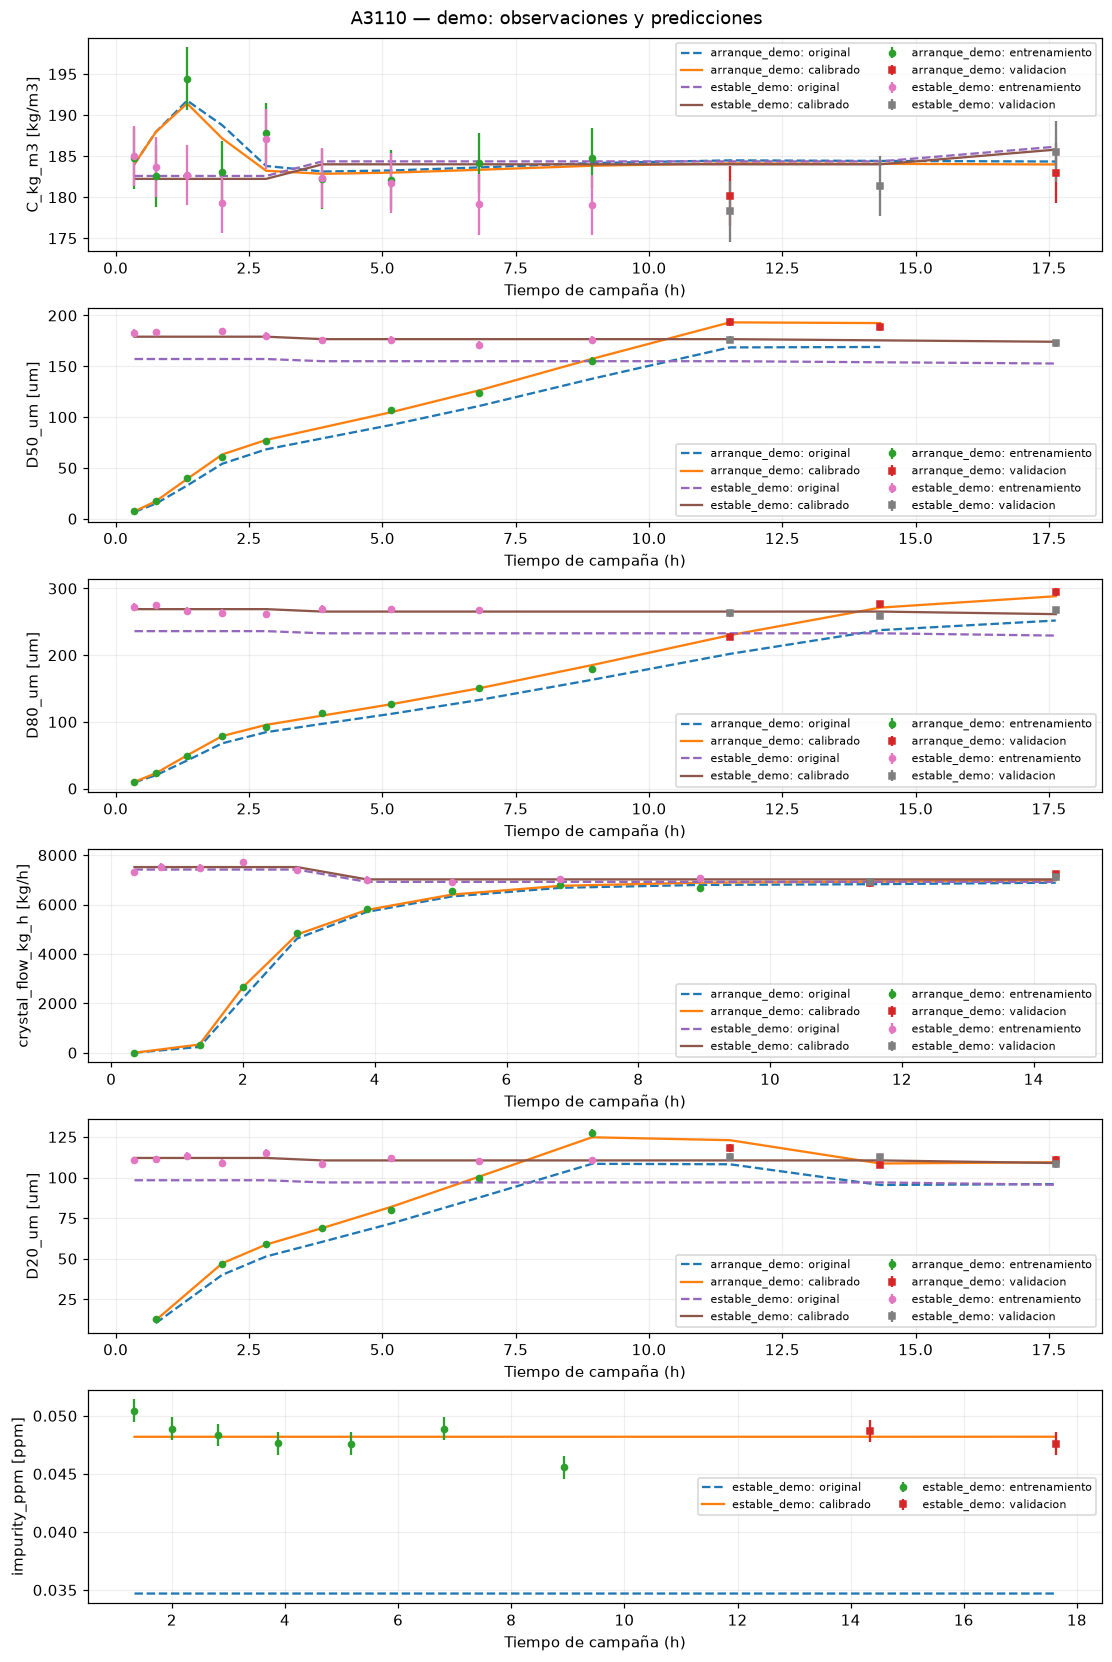

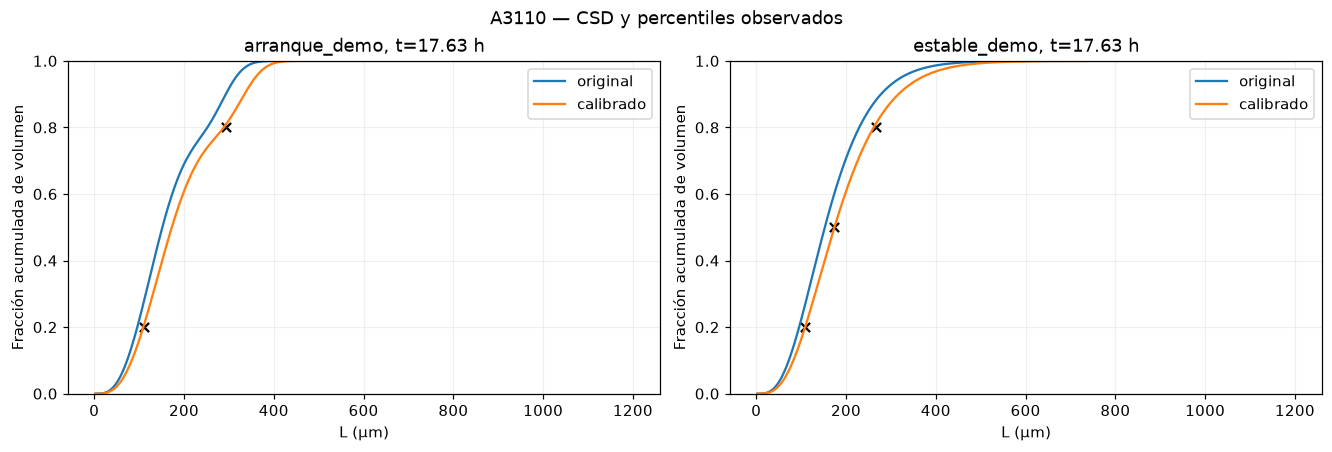

,campaign,model,tail_fraction,solid_volume_fraction
0,arranque_demo,original,2.363783e-123,0.011734
1,arranque_demo,calibrado,1.284737e-103,0.011903
2,estable_demo,original,1.182359e-09,0.010883
3,estable_demo,calibrado,2.763281e-08,0.011051


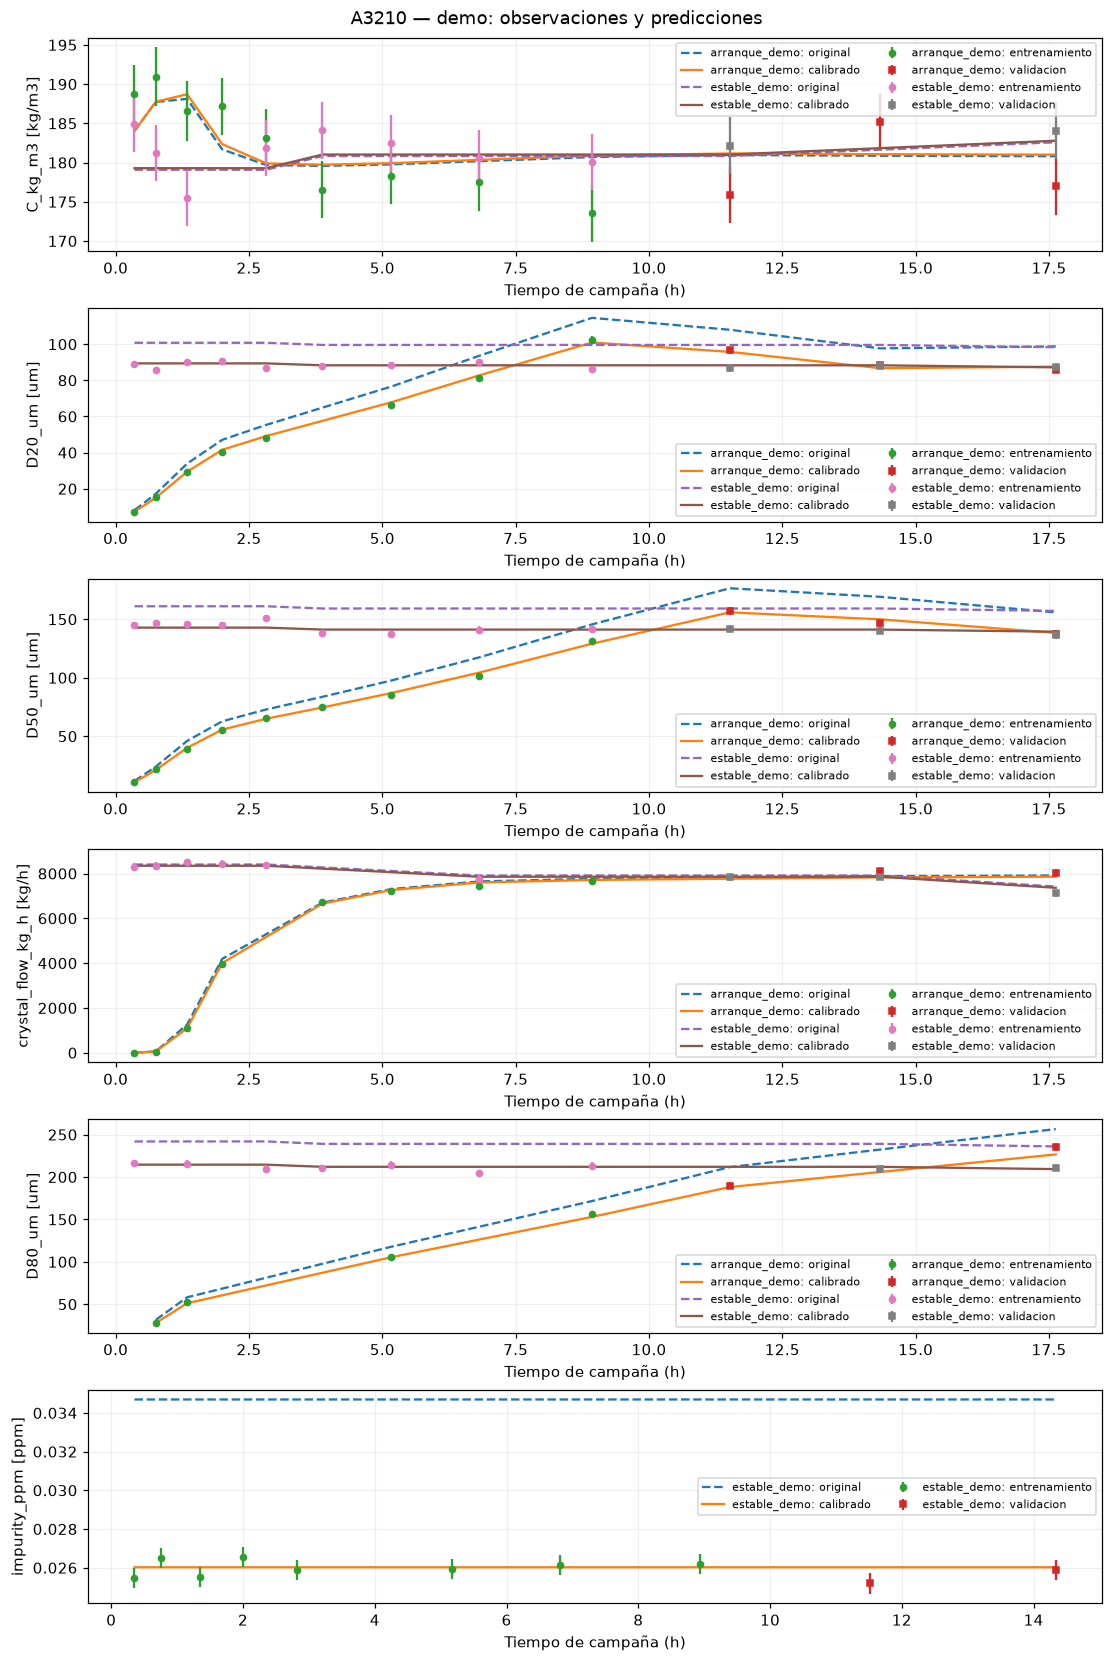

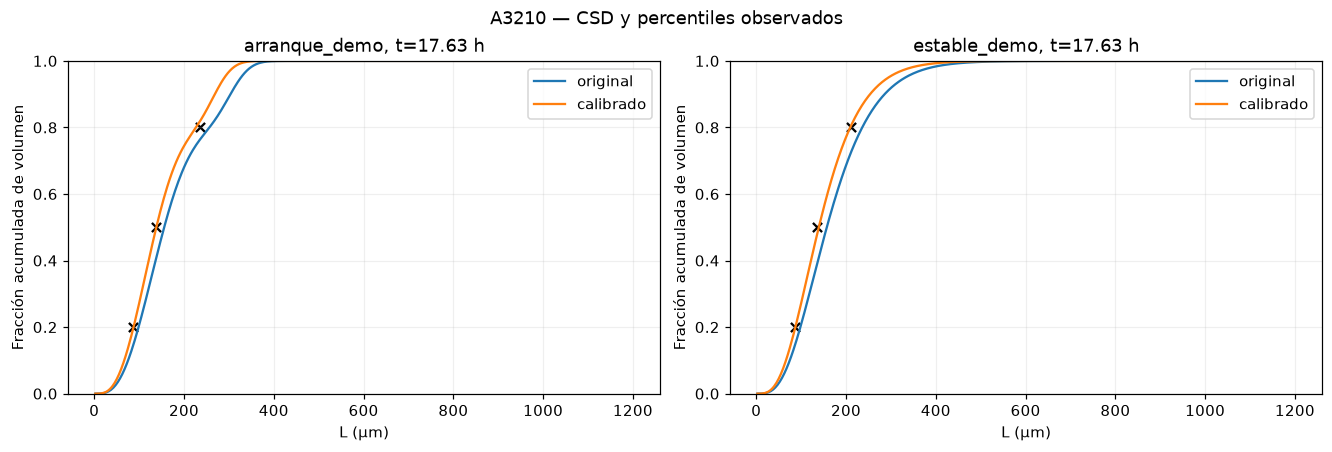

,campaign,model,tail_fraction,solid_volume_fraction
0,arranque_demo,original,1.358383e-117,0.013416
1,arranque_demo,calibrado,2.408268e-136,0.013323
2,estable_demo,original,2.448005e-09,0.012578
3,estable_demo,calibrado,9.775329e-11,0.012485


In [7]:
def plot_results(equipment, result):
    obs = result['comparison']
    variables = list(obs.variable.unique())
    fig, axes = plt.subplots(len(variables), 1, figsize=(10, 2.5*len(variables)), squeeze=False, constrained_layout=True)
    for ax,variable in zip(axes[:,0],variables):
        for experiment, rows in obs[obs.variable == variable].groupby('experiment'):
            campaign = result['data'][result['data'].experiment == experiment]
            # Curvas en los tiempos reales: no se inventan observaciones entre ellos.
            times = np.sort(rows.time.unique())
            initial, _, _ = simulate_campaign(campaign, result['initial'], times)
            final, _, _ = simulate_campaign(campaign, result['parameters'], times)
            ax.plot(times/3600, initial[variable], '--', label=f'{experiment}: original')
            ax.plot(times/3600, final[variable], '-', label=f'{experiment}: calibrado')
            for subset, group in rows.groupby('subset'):
                ax.errorbar(group.time/3600, group.value, yerr=group.sd.fillna(0), linestyle='none',
                            marker='o' if subset == 'entrenamiento' else 's', markersize=4,
                            label=f'{experiment}: {subset}')
        ax.set(xlabel='Tiempo de campaña (h)', ylabel=f'{variable} [{next(iter(UNITS[variable]))}]')
        ax.legend(fontsize=7, ncol=2)
    fig.suptitle(f'{equipment} — {MODE}: observaciones y predicciones')
    plt.show()
    campaigns = list(obs.experiment.unique())
    fig, axes = plt.subplots(1,len(campaigns), figsize=(6*len(campaigns),4), squeeze=False, constrained_layout=True)
    diagnostics = []
    for ax,experiment in zip(axes[0],campaigns):
        campaign = result['data'][result['data'].experiment == experiment]
        sizes = obs[(obs.experiment == experiment) & obs.variable.str.startswith('D')]
        time = sizes.time.max() if len(sizes) else campaign.time.max()
        for label,p in [('original',result['initial']),('calibrado',result['parameters'])]:
            trajectory, N, grid = simulate_campaign(campaign,p,[time])
            w = grid['q'][3]*N[-1]
            if w.sum() > 0:
                ax.plot(grid['edges'][1:]*1e6,np.cumsum(w)/w.sum(),label=label)
            metrics = trajectory.iloc[-1]
            diagnostics.append(dict(campaign=experiment,model=label,tail_fraction=metrics.tail_fraction,
                                    solid_volume_fraction=metrics.phi_s))
        for _,row in sizes[sizes.time == time].iterrows():
            ax.scatter(row.value, {'D20_um':.2,'D50_um':.5,'D80_um':.8}[row.variable], marker='x', color='black')
        ax.set(xlabel='L (µm)',ylabel='Fracción acumulada de volumen',title=f'{experiment}, t={time/3600:.2f} h',ylim=(0,1))
        ax.legend()
    fig.suptitle(f'{equipment} — CSD y percentiles observados')
    plt.show()
    diagnostics = pd.DataFrame(diagnostics)
    display(diagnostics)
    if (diagnostics.tail_fraction > NUM['tail_tolerance']).any():
        warnings.warn(f'{equipment}: fuga por Lmax relevante; ampliar dominio antes de interpretar ajuste.')
    if (diagnostics.solid_volume_fraction > NUM['solid_volume_fraction_limit']).any():
        warnings.warn(f'{equipment}: fracción sólida excede el límite original.')

for equipment,result in RESULTS.items():
    plot_results(equipment,result)

## Pruebas funcionales reproducibles

Las pruebas usan aserciones y no necesitan pytest. Verifican unidades, observaciones faltantes, rechazo de duplicados/sintéticos/bases incorrectas, tiempos irregulares, pesos, segregación temporal, conservación, reutilización del modelo, independencia de equipos y recuperación sintética sin ruido. La prueba sin ruido comprueba el ajuste desde otros valores iniciales; no solo que el simulador reproduzca su propia salida en los parámetros verdaderos. No se exige que cada variable mejore individualmente bajo ruido: el criterio minimizado es multivariable.

In [8]:
def run_tests():
    passed = []
    def check(name, condition):
        assert condition, name
        passed.append(name)
    def rejects(name, action):
        try:
            action()
        except (ValueError, AssertionError):
            passed.append(name)
        else:
            raise AssertionError(name)
    check('Solo parámetros autorizados', set(SELECTED) <= ALLOWED)
    check('Original intacto', hashlib.sha256(MODEL_FILE.read_bytes()).hexdigest() == MODEL_SHA256)
    if MODE == 'demo':
        repeated,_ = make_demo(SEED)
        check('Ruido reproducible', DATA.equals(repeated))
        check('Dos equipos independientes', len(RESULTS) == 2 and RESULTS['A3110']['parameters'] is not RESULTS['A3210']['parameters'])
    sample = pd.DataFrame([dict(crystallizer='A3110',experiment='test',time=60,time_unit='min',
                               regime='steady',variable='D50_um',value=.3,unit='mm',basis='volume',
                               role='observation',origin='measured',sd=.01)])
    converted = normalize_data(sample,'experimental')
    check('Unidades de valor, sd y tiempo', np.allclose(converted[['value','sd','time']].iloc[0].astype(float),[300,10,3600]))
    missing = pd.concat([sample,sample.assign(value=np.nan)],ignore_index=True)
    check('Faltantes no se inventan', len(normalize_data(missing,'experimental')) == 1)
    rejects('Duplicados rechazados', lambda: normalize_data(pd.concat([sample,sample]),'experimental'))
    rejects('Sintéticos rechazados en modo real', lambda: normalize_data(sample.assign(origin='synthetic'),'experimental'))
    rejects('Unidad desconocida rechazada', lambda: normalize_data(sample.assign(unit='inch'),'experimental'))
    rejects('Base numérica de percentil rechazada', lambda: normalize_data(sample.assign(basis='number'),'experimental'))
    rejects('Tiempo negativo rechazado', lambda: normalize_data(sample.assign(time=-1),'experimental'))
    rejects('sd no positiva rechazada', lambda: normalize_data(sample.assign(sd=0),'experimental'))
    rejects('Identificador faltante rechazado', lambda: normalize_data(sample.assign(experiment=np.nan),'experimental'))
    if Path('plantilla_datos_cristalizadores.xlsx').exists():
        rejects('Importación Excel: plantilla vacía rechazada',lambda: read_experiments(Path('plantilla_datos_cristalizadores.xlsx')))
    dated = pd.concat([sample.assign(time='2026-01-01T00:00:00Z'),
                       sample.assign(time='2026-01-01T00:07:00Z')],ignore_index=True)
    check('Fechas y reloj irregular', np.array_equal(normalize_data(dated,'experimental').time,[0.,420.]))
    controls = pd.DataFrame({'variable':['temperature_C','temperature_C'], 'time':[0.,100.], 'value':[40.,42.]})
    check('Interpolación operacional causal', operation_at(controls,50.,parameters_for('A3110'))['crystallizer_temperature_C'] == 40.)
    rejects('Sin extrapolación operacional',lambda: operation_at(controls,101.,parameters_for('A3110')))
    inconsistent = pd.DataFrame({'variable':['feed_flow_m3_s','residence_time'], 'time':[0.,0.], 'value':[1.,1.]})
    rejects('Consistencia Q V tau',lambda: operation_at(inconsistent,0.,parameters_for('A3110')))
    wide = sample.drop(columns=['variable','value','unit','role']).assign(D50_mm=.3)
    check('Formato ancho', normalize_data(tidy_sheet(wide,'observation'),'experimental').value.iloc[0] == 300)
    interpolated = normalize_data(sample.assign(origin='interpolated'),'experimental')
    check('Interpolaciones no son observaciones', not interpolated.origin.isin(['measured','synthetic']).any())
    for equipment,result in RESULTS.items():
        c = result['comparison']
        check(equipment+': objetivo mejora', result['final_cost'] <= result['initial_cost']+1e-8)
        check(equipment+': parámetros en límites', all(PARAMETER_CONFIG[k][1] <= result['parameters'][k] <= PARAMETER_CONFIG[k][2] for k in result['names']))
        for _,group in c.groupby('experiment'):
            a,b = group[group.subset == 'entrenamiento'], group[group.subset == 'validacion']
            check(equipment+': separación temporal '+str(group.experiment.iloc[0]), b.empty or a.time.max() < b.time.min())
        if MODE == 'demo':
            p = result['initial']
            campaign = result['data'][result['data'].experiment == 'arranque_demo']
            times = np.array([0., 137., 421., 1009.])
            tr,N,grid = simulate_campaign(campaign,p,times)
            check(equipment+': tiempos exactos irregulares', np.array_equal(tr.index.to_numpy(),times))
            check(equipment+': positividad', np.min(N) >= 0 and tr.C_kg_m3.min() >= 0)
            check(equipment+': D50 original', np.isclose(percentile(N[-1],grid,.5),MODEL['d50'](N[-1],grid)))
            q = operation_at(campaign[campaign.role == 'input'],0.,p)
            expected = MODEL['INITIAL']['C_kg_m3']+MODEL['feed'](q)['KNO3']*times/q['residence_time']
            check(equipment+': balance dinámico', np.allclose(tr.mass_inventory_kg_m3,expected,rtol=2e-6,atol=1e-6))
            # Comparar integrador nuevo con integrador SSP-RK2 original, misma operación y estado.
            old = MODEL['integrate'](q,{**NUM,'duration_tau':.1,'sample_every_tau':.1,'max_step_s':2.})
            now,_,_ = simulate_campaign(campaign,p,[.1*q['residence_time']])
            check(equipment+': concordancia integrador original', np.isclose(now.C_kg_m3.iloc[-1],old['trajectory'].C_kg_m3.iloc[-1],rtol=2e-4))
            steady = result['data'][result['data'].experiment == 'estable_demo']
            source = MODEL['stationary_dpbe'](operation_at(steady[steady.role == 'input'],0.,p),NUM)
            same,_,_ = simulate_campaign(steady,p,[0.])
            check(equipment+': estacionario original', np.isclose(same.C_kg_m3.iloc[0],source['C']))
            # Kd no altera el DPBE, solo el postproceso original.
            altered = deepcopy(p); altered['Kd'] *= 1.1
            same2,_,_ = simulate_campaign(steady,altered,[0.])
            check(equipment+': desacople físico Kd', np.isclose(same.D50_um.iloc[0],same2.D50_um.iloc[0]) and same.impurity_ppm.iloc[0] != same2.impurity_ppm.iloc[0])
    if MODE == 'demo':
        equipment = 'A3110'
        data = RESULTS[equipment]['data'].copy()
        obs = OBSERVATIONS[OBSERVATIONS.crystallizer == equipment].copy()
        truth = parameters_for(equipment,DEMO_TRUTH[equipment])
        obs['value'] = predict(obs,data,truth)
        exact = fit_equipment(equipment,data,obs)
        check('Recuperación sin ruido', all(np.isclose(exact['parameters'][k],truth[k],rtol=.015) for k in exact['names']))
        check('Ajuste sin ruido converge', exact['optimizer'].success and exact['final_cost'] < 1e-7)
    check('Original sigue intacto', hashlib.sha256(MODEL_FILE.read_bytes()).hexdigest() == MODEL_SHA256)
    print(f'{len(passed)} pruebas aprobadas.')
    return passed

TEST_RESULTS = run_tests()
display(pd.DataFrame({'prueba':TEST_RESULTS,'resultado':'OK'}))

45 pruebas aprobadas.


,prueba,resultado
0,Solo parámetros autorizados,OK
1,Original intacto,OK
2,Ruido reproducible,OK
3,Dos equipos independientes,OK
4,"Unidades de valor, sd y tiempo",OK
5,Faltantes no se inventan,OK
6,Duplicados rechazados,OK
7,Sintéticos rechazados en modo real,OK
8,Unidad desconocida rechazada,OK
9,Base numérica de percentil rechazada,OK


## Uso con mediciones reales

Guardar una copia de la plantilla y completar operación y mediciones por equipo y campaña. En modo real, definir `INITIAL_STATES` para cada arranque, incluyendo C y la población inicial medida (cero solo si el arranque realmente está libre de cristales). Declarar `steady` únicamente si se verificó el régimen experimentalmente. Usar `MODE='experimental'`, ajustar `DATA_FILE` y ejecutar desde el principio. Un archivo ausente, vacío o incompatible causa un error explícito. Cambiar unidades/encabezados mediante configuración, sin tocar la lógica de ajuste.

Interpretar primero las métricas de validación, luego las mejoras de entrenamiento y los diagnósticos. Revisar parámetros en límites, identificabilidad y cola de la CSD. Si se seleccionan g/b, se necesita variación de sobresaturación suficiente; los datos de un solo estado estacionario no identifican cinco parámetros. Los resultados sintéticos solo verifican el software. Los originales, incluidos los Excel de planta, permanecen sin cambios.